In [ ]:
#Download the source code of the Mask R-CNN mode & install requests module
!git clone https://github.com/tensorflow/tpu/
!pip install requests

#Import libraries
from IPython import display
import pandas as pd
from google.colab import files
import requests
from PIL import Image
from PIL import ImageFile
from google.colab import drive
import os,csv,time,sys,itertools
from datetime import timedelta
ImageFile.LOAD_TRUNCATED_IMAGES = True
import numpy as np
#%tensorflow_version 1.x
import tensorflow.compat.v1 as tf
sys.path.insert(0, 'tpu/models/official')
sys.path.insert(0, 'tpu/models/official/mask_rcnn')
import coco_metric
from mask_rcnn.object_detection import visualization_utils

fatal: destination path 'tpu' already exists and is not an empty directory.


In [ ]:
from google.colab import drive
import os
import gdown
drive.mount('/content/drive', force_remount=True)

TRAFFIC_MONITORING_DIR = '/content/drive/My Drive/Traffic_monitoring'

# Create the directory if it does not exist
if not os.path.exists(TRAFFIC_MONITORING_DIR):
    os.makedirs(TRAFFIC_MONITORING_DIR)
    print(f"Directory '{TRAFFIC_MONITORING_DIR}' created.")
else:
    print(f"Directory '{TRAFFIC_MONITORING_DIR}' already exists.")

traffic_image_link = 'https://drive.google.com/uc?id=1wzFdCRskjuGN8QpmZ1-v8juwgZ-rlx-H'

# Specify the destination path where you want to save the file
TRAFFIC_IMAGE_INPUT = TRAFFIC_MONITORING_DIR + '/Wed1-20-20.csv'

# Download the file
gdown.download(traffic_image_link, TRAFFIC_IMAGE_INPUT, quiet=False)

Mounted at /content/drive
Directory '/content/drive/My Drive/Traffic_monitoring' already exists.


Downloading...
From: https://drive.google.com/uc?id=1x-alWK8WhLSKc2XoQ4eSuB5UPiJFXfnV
To: /content/drive/My Drive/Traffic_monitoring/Wed1-20-20.csv
100%|██████████| 3.98k/3.98k [00:00<00:00, 6.62MB/s]


'/content/drive/My Drive/Traffic_monitoring/Wed1-20-20.csv'

In [ ]:
#Load COCO index mapping
ID_MAPPING = { 1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle', 5: 'airplane', 6: 'bus', 7: 'train', 8: 'truck',9: 'boat', 10: 'traffic light',
    11: 'fire hydrant', 13: 'stop sign', 14: 'parking meter',15: 'bench', 16: 'bird', 17: 'cat',18: 'dog',19: 'horse',20: 'sheep',
    21: 'cow', 22: 'elephant',23: 'bear',24: 'zebra',25: 'giraffe', 27: 'backpack', 28: 'umbrella',31: 'handbag',32: 'tie',  33: 'suitcase',
    34: 'frisbee', 35: 'skis',36: 'snowboard', 37: 'sports ball', 38: 'kite',39: 'baseball bat', 40: 'baseball glove', 41: 'skateboard',
    42: 'surfboard', 43: 'tennis racket',44: 'bottle', 46: 'wine glass',47: 'cup',48: 'fork',49: 'knife',50: 'spoon',51: 'bowl',
    52: 'banana',53: 'apple', 54: 'sandwich',55: 'orange',56: 'broccoli',57: 'carrot', 58: 'hot dog',59: 'pizza',60: 'donut', 61: 'cake',62: 'chair',
    63: 'couch', 64: 'potted plant',65: 'bed', 67: 'dining table',70: 'toilet',72: 'tv',73: 'laptop',74: 'mouse',75: 'remote',76: 'keyboard',
    77: 'cell phone', 78: 'microwave',79: 'oven',80: 'toaster', 81: 'sink',82: 'refrigerator', 84: 'book',85: 'clock',86: 'vase',87: 'scissors',
    88: 'teddy bear',89: 'hair drier',90: 'toothbrush',
}
category_index = {k: {'id': k, 'name': ID_MAPPING[k]} for k in ID_MAPPING}

In [ ]:
#Create a Tensorflow session to run the inference. You can either connect to a TPU or a normal CPU backend.
use_tpu = True
if use_tpu:
  import os
  import pprint

  assert 'COLAB_TPU_ADDR' in os.environ, 'ERROR: Not connected to a TPU runtime;'
  TPU_ADDRESS = 'grpc://' + os.environ['COLAB_TPU_ADDR']
  print('TPU address is', TPU_ADDRESS)

  session = tf.Session(TPU_ADDRESS, graph=tf.Graph())
  print('TPU devices:')
  pprint.pprint(session.list_devices())
else:
  session = tf.Session(graph=tf.Graph())

#Loading the coco pretrained seved model from the public GCS bucket
saved_model_dir = 'gs://cloud-tpu-checkpoints/mask-rcnn/1555659850'
_ = tf.saved_model.loader.load(session, ['serve'], saved_model_dir)

TPU address is grpc://10.47.65.90:8470
TPU devices:
[_DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:CPU:0, CPU, -1, -974777058321923782),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU_SYSTEM:0, TPU_SYSTEM, 8589934592, 6726053334835722031),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU:0, TPU, 17179869184, 115513889783398607),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU:1, TPU, 17179869184, 1464839896190072805),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU:2, TPU, 17179869184, -509324242713430862),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU:3, TPU, 17179869184, 3638696940064793779),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU:4, TPU, 17179869184, -7963365639870983068),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU:5, TPU, 17179869184, 462360671538259435),
 _DeviceAttributes(/job:tpu_worker/replica:0/task:0/device:TPU:6, TPU, 17179869184, 4268260939612

In [ ]:
#Import a previous generated and uploaded csv from dropbox
#Remember to set 1 instead of 0 in the last part of the URL
def read_lta_csv(google_url):
  df = pd.read_csv(google_url, sep=',', lineterminator='\r')
  #print(df)
  images = df.loc[:,'Image']
  cam_id = df.loc[:,'Cam_id']
  timestamp_sg_time = df.loc[:,'Timestamp_sg_time']
  url = df.loc[:,'Image']

  return images,cam_id,timestamp_sg_time,url


In [ ]:
## Loading each image to apply the R-CNN
def process_data(images,cam_id,timestamp_sg_time,url):
  camera_number= str(cam_id)
  print("camera =",camera_number)
  df_app = []
  bad_images=[]
  bad_dates=[]

  for i in range(len(images)):
    camera = str(cam_id)
    try:
      site = images[i]
      img_data = requests.get(site).content
      with open('image_name.jpg', 'wb') as handler:
          handler.write(img_data)

      image_path = 'image_name.jpg'

      with open(image_path, 'rb') as f:
        np_image_string = np.array([f.read()])

      image = Image.open(image_path)
      width, height = image.size
      np_image = np.array(image.getdata()).reshape(height, width, 3).astype(np.uint8)

      #display.display(display.Image(image_path, width=1024)) #Image preview

      #Perform image segmentation and retrieve the predictions
      num_detections, detection_boxes, detection_classes, detection_scores,detection_masks, image_info = session.run(
          ['NumDetections:0', 'DetectionBoxes:0', 'DetectionClasses:0',
          'DetectionScores:0', 'DetectionMasks:0', 'ImageInfo:0'],
          feed_dict={'Placeholder:0': np_image_string})

      num_detections = np.squeeze(num_detections.astype(np.int32), axis=(0,))
      detection_boxes = np.squeeze(detection_boxes * image_info[0, 2], axis=(0,))[0:num_detections]
      detection_scores = np.squeeze(detection_scores, axis=(0,))[0:num_detections]
      detection_classes = np.squeeze(detection_classes.astype(np.int32), axis=(0,))[0:num_detections]
      instance_masks = np.squeeze(detection_masks, axis=(0,))[0:num_detections]
      ymin, xmin, ymax, xmax = np.split(detection_boxes, 4, axis=-1)
      processed_boxes = np.concatenate([xmin, ymin, xmax - xmin, ymax - ymin], axis=-1)
      bounding_box_area = (xmax - xmin) * (ymax - ymin)
      segmentations = coco_metric.generate_segmentation_from_masks(instance_masks, processed_boxes, height, width)
      image_area = width * height
      proportion_bounding_box = (bounding_box_area / image_area)*100

      #print("Width, height : ", width, height)
      #print("num_detections : ",num_detections)
      #print("detection_boxes : ",detection_boxes)
      #print("detection_scores : ",detection_scores)
      #print("detection_classes : ",detection_classes)
      #print(ymin, xmin, ymax, xmax)
      #print("bounding_box_area : ",bounding_box_area)

      #Visualze the detections results and print a dataframe generated by detection class and detection score
      max_boxes_to_draw = 70
      min_score_thresh = 0.6
      image_with_detections = visualization_utils.visualize_boxes_and_labels_on_image_array(
          np_image,
          detection_boxes,
          detection_classes,
          detection_scores,
          category_index,
          instance_masks=segmentations,
          use_normalized_coordinates=False,
          max_boxes_to_draw=max_boxes_to_draw,
          min_score_thresh=min_score_thresh)
      output_image_path = 'test_results.jpg'
      Image.fromarray(image_with_detections.astype(np.uint8)).save(output_image_path)
      display.display(display.Image(output_image_path, width=1024)) #Processed image preview

      df = pd.DataFrame(list(zip(itertools.repeat(i),
                                itertools.repeat(camera_number),
                                detection_classes,
                                detection_scores,
                                itertools.repeat(timestamp_sg_time[i]),
                                itertools.repeat(url[i]),
                                ymin.ravel(),xmin.ravel(), ymax.ravel(), xmax.ravel(),
                                bounding_box_area.ravel(), proportion_bounding_box.ravel(),
                                instance_masks.ravel())),
              columns =['Image_id', 'Cam_ID','Detection_Class',
                        'Detection_Score','Timestamp_sg_time','URL',
                        'ymin', 'xmin', 'ymax', 'xmax','Bounding_box_area','Proportion_bounding_box_0_100'
                        ,'Segmentation_pixels'])
      df_app.append(df)
      #print(df)
      print(i)
    except Exception as e:
      #print('break time: ', times[i])
      print("Exception :: ",str(e))
      print("Exception Date :: ",timestamp_sg_time[i])
      print('break time:', i)
      bad_images.append(images[i])
      bad_dates.append(timestamp_sg_time[i])
      #break

  #Download a simple dataframe with the detections classes and detection scores
  df_simple = pd.concat(df_app)

  a = df_simple.dtypes
  #print (a)
  file_name = "output_cnn.csv"

  #To save contents to google drive
  output_file_full_path = os.path.join(TRAFFIC_MONITORING_DIR, file_name)
  print("output_file_full_path = ",output_file_full_path)
  df_simple.to_csv(output_file_full_path)
  files.download(output_file_full_path)
  print(df_simple.iloc[0])

  for i in range(len(bad_dates)):
    print("Exception occured at",bad_dates[i],images[i] )


25
camera = 0     \n1701
1     \n1701
2     \n1701
3     \n1701
4     \n1701
5     \n1701
6     \n1701
7     \n1701
8     \n1701
9     \n1701
10    \n1701
11    \n1701
12    \n1701
13    \n1701
14    \n1701
15    \n1701
16    \n1701
17    \n1701
18    \n1701
19    \n1701
20    \n1701
21    \n1701
22    \n1701
23    \n1701
24        \n
Name: Cam_id, dtype: object


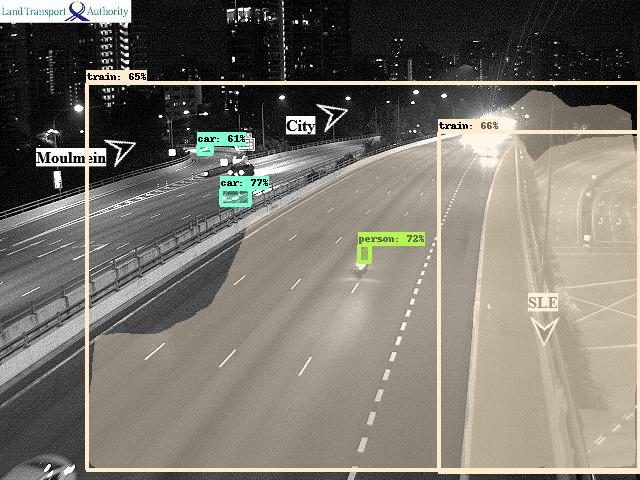

0


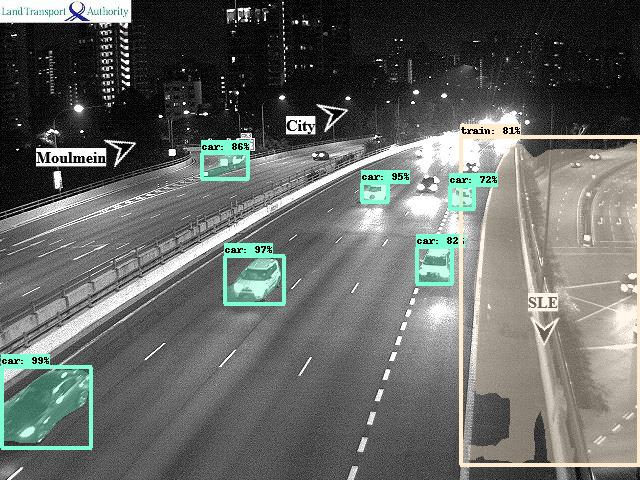

1


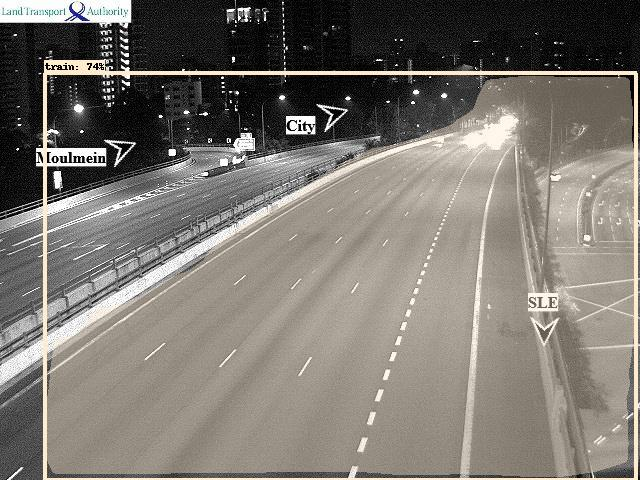

2


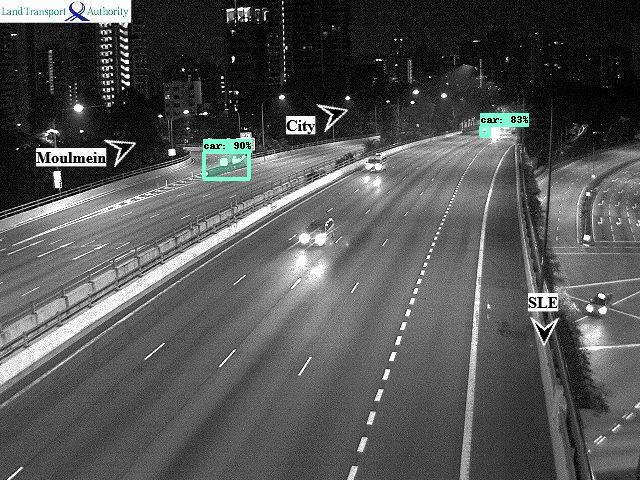

3


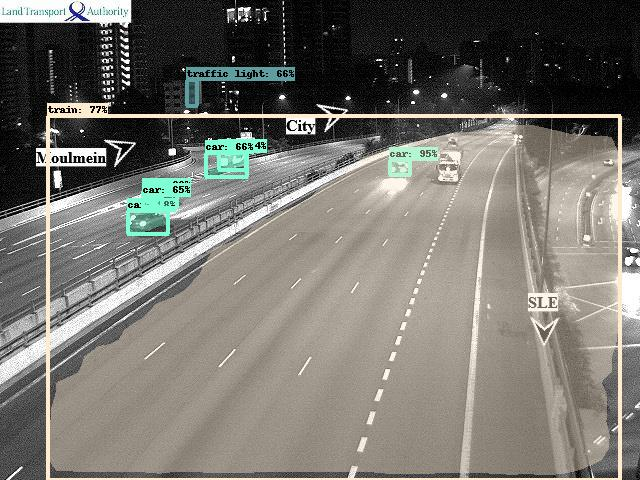

4


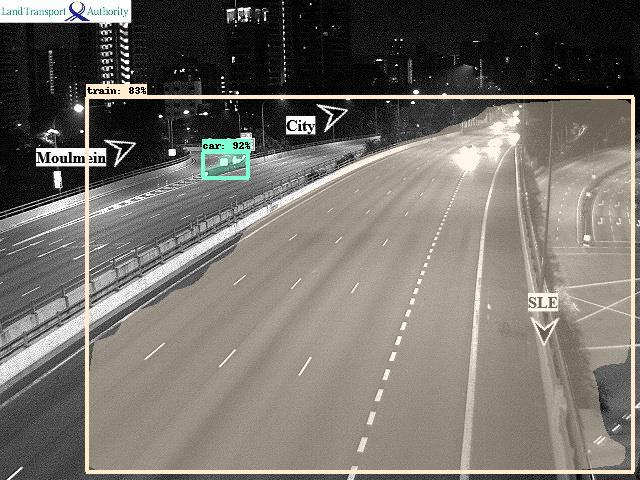

5


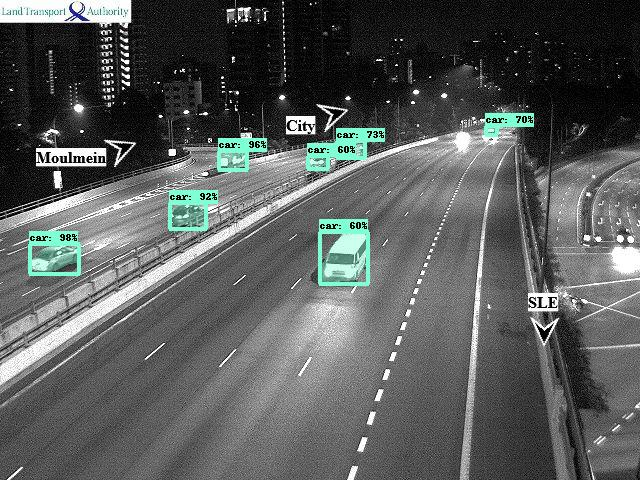

6


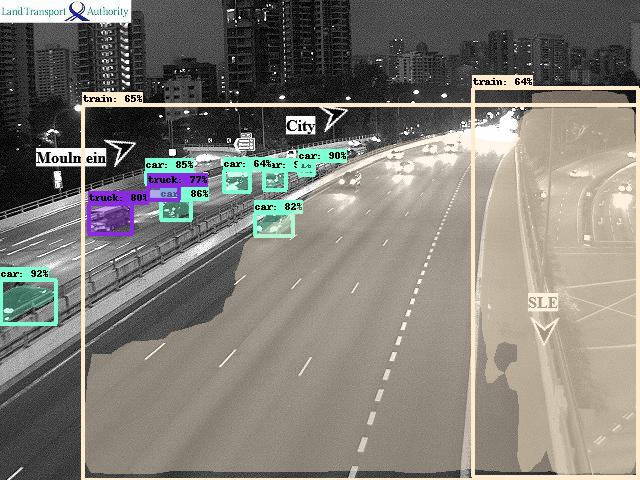

7


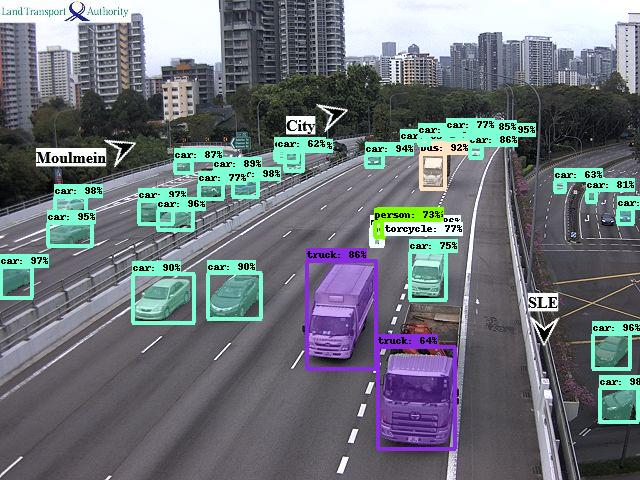

8


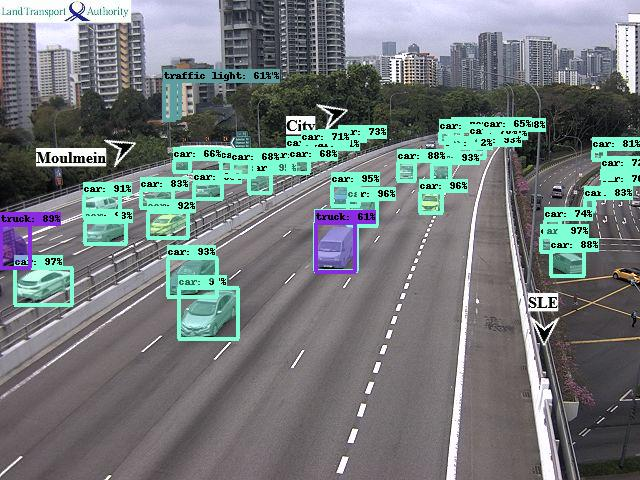

9


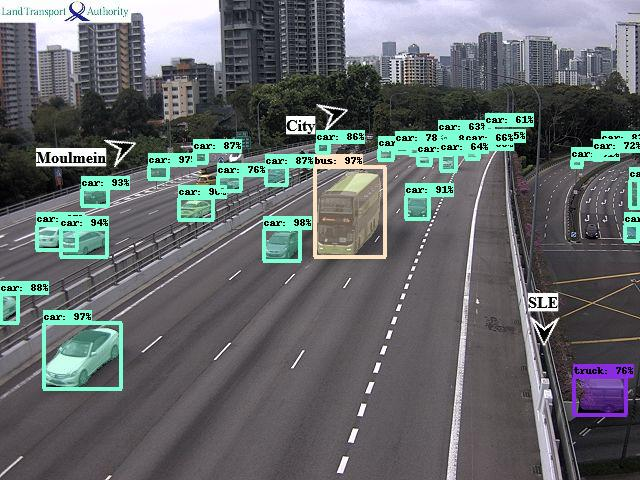

10


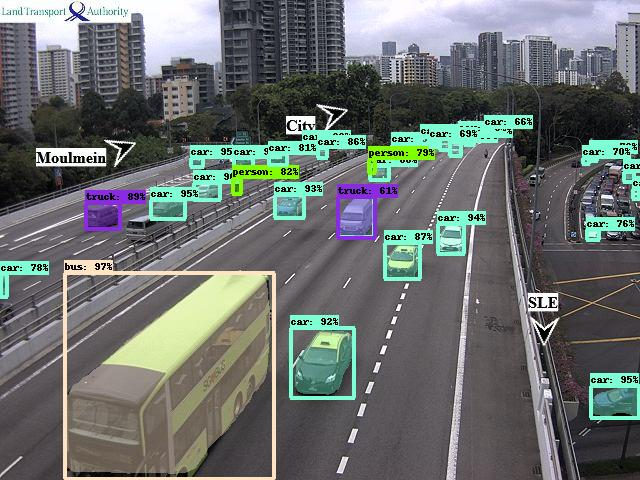

11


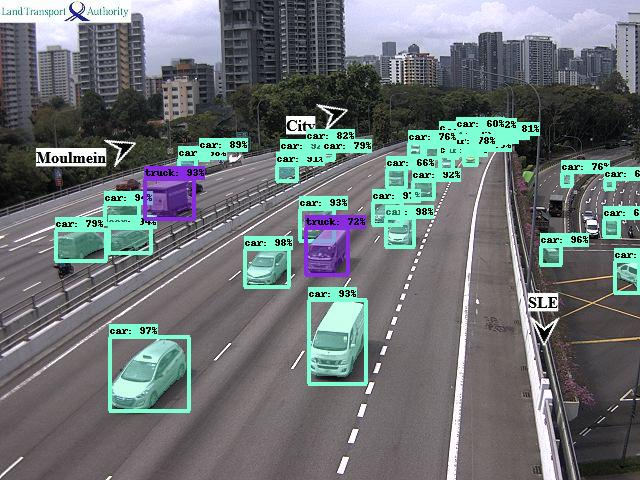

12


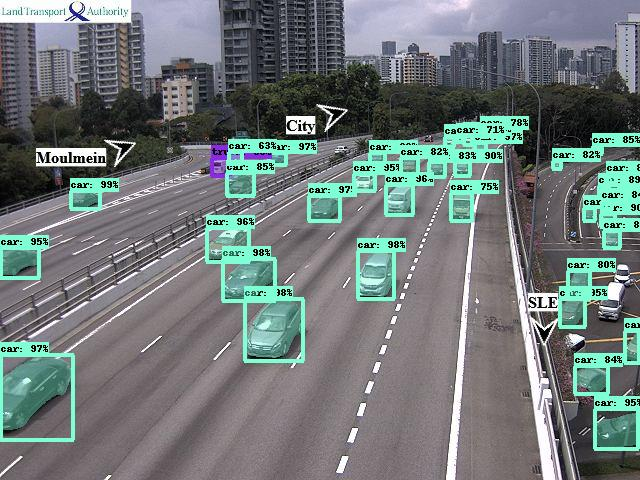

13


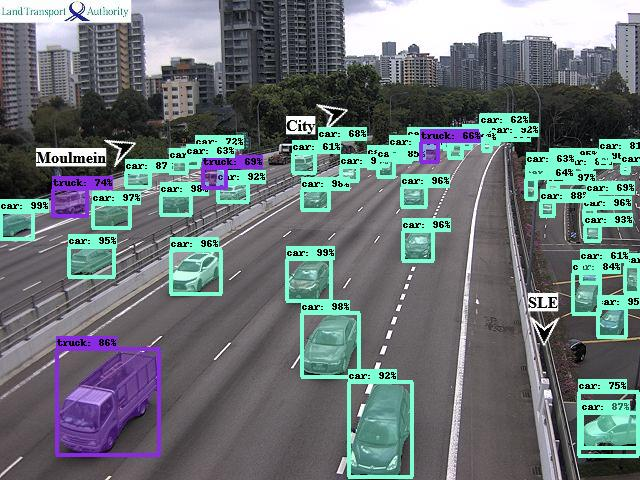

14


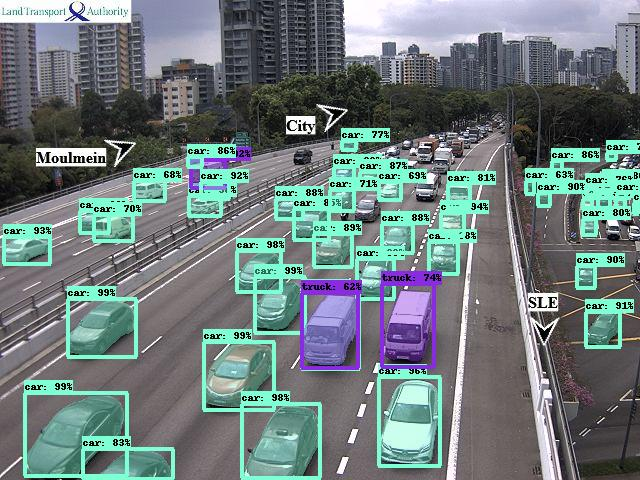

15


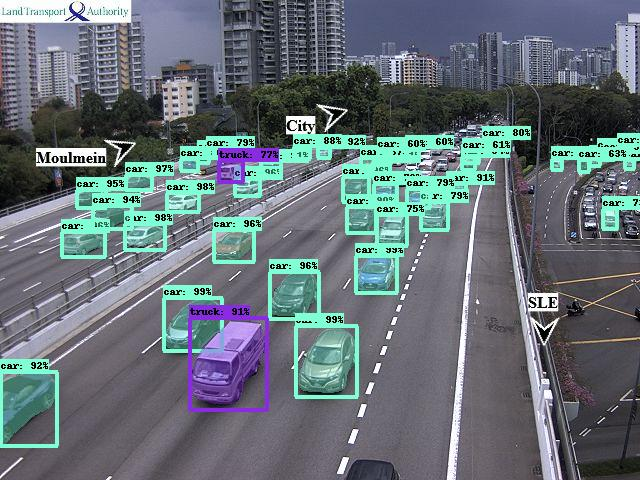

16


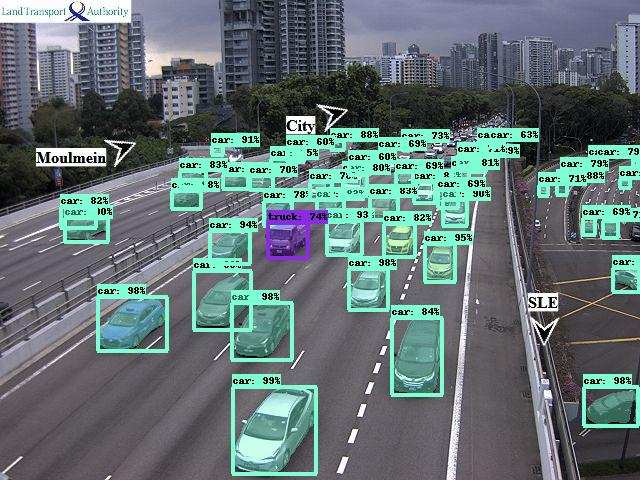

17


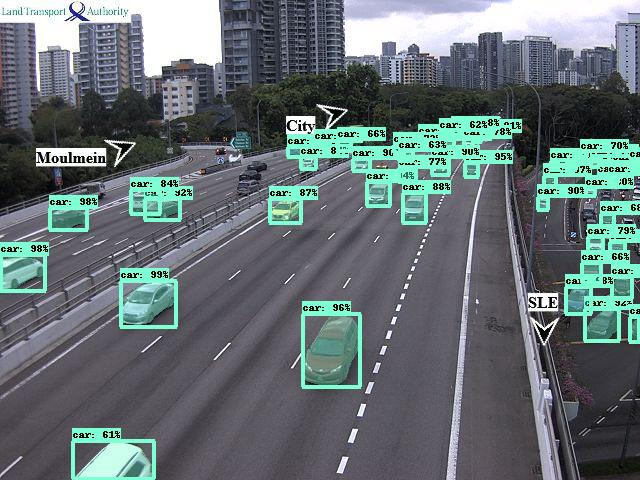

18


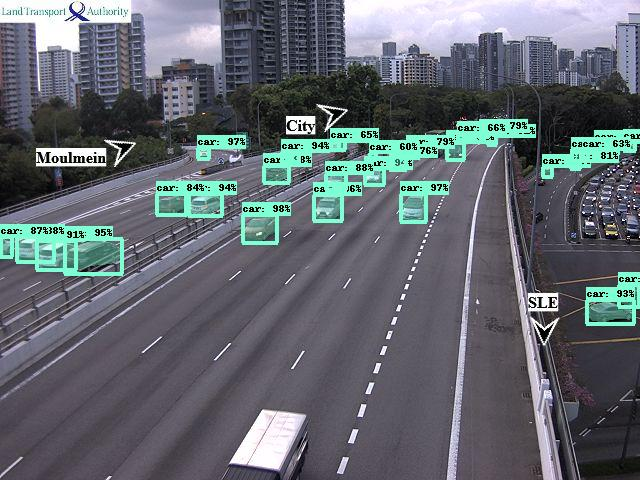

19


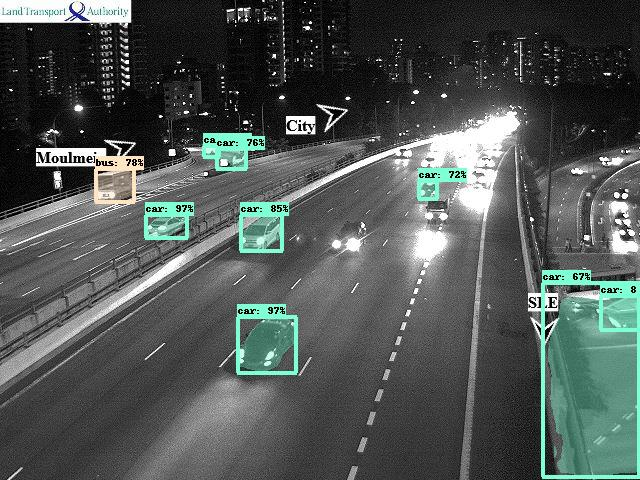

20


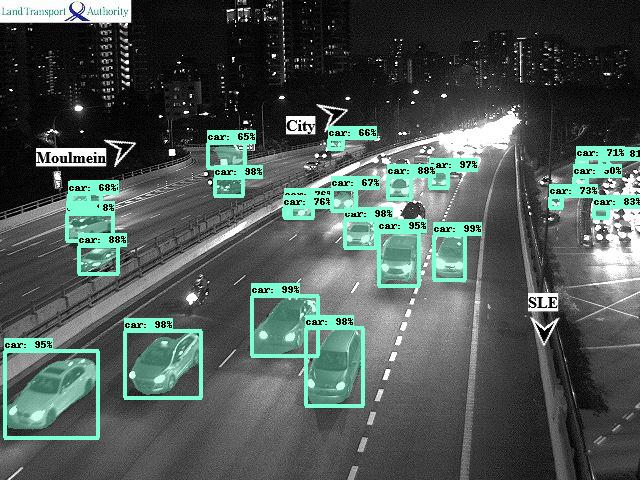

21


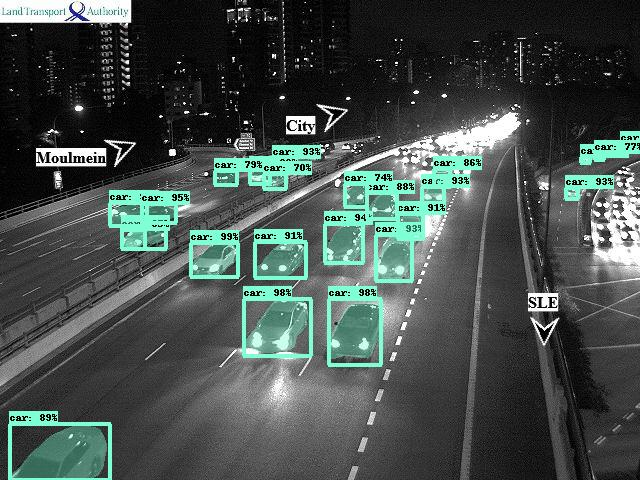

22


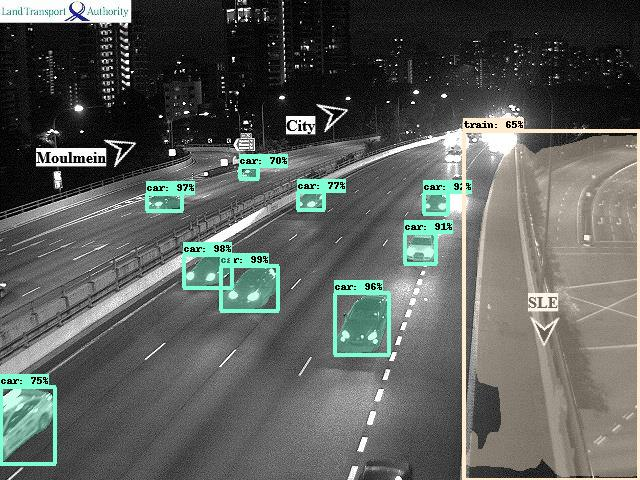

23
Exception ::  Invalid URL 'nan': No scheme supplied. Perhaps you meant https://nan?
Exception Date ::  nan
break time: 24
output_file_full_path =  /content/drive/My Drive/Traffic_monitoring/output_cnn.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Image_id                                                                         0
Cam_ID                           0     \n1701\n1     \n1701\n2     \n1701\n3   ...
Detection_Class                                                                  3
Detection_Score                                                            0.77014
Timestamp_sg_time                                              2020-01-20 00:00:00
URL                              https://images.data.gov.sg/api/traffic-images/...
ymin                                                                    189.250961
xmin                                                                     220.76059
ymax                                                                    204.911514
xmax                                                                    250.108307
Bounding_box_area                                                       459.601471
Proportion_bounding_box_0_100                                              0.14961
Segm

In [ ]:
images,cam_id,timestamp_sg_time,url = read_lta_csv(TRAFFIC_IMAGE_INPUT)
print(len(images))
process_data(images,cam_id,timestamp_sg_time,url)